<a href="https://colab.research.google.com/github/boluwatiseoyetunji-rgb/G5_Mindspire_Stemnestacademy/blob/main/Setup_plus_first_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

print("scikit-learn is ready")

scikit-learn is ready


In [ ]:
complaints = [
    "I can't log in to my account",
    "My order never arrived",
    "The app keeps crashing",
    "I was charged twice",
    "My account was hacked",
    "The delivery was damaged",
]

enquiries = [
    "What are you opening hours?",
    "Do you deliver to Accra?",
    "How long does delivery take?",
    "What payment methods do you accept?",
    "Where is my nearest store?",
    "Can I return an item?",
]

texts = complaints + enquiries
labels = ["complaints"] * 6 + ["enquiries"] * 6

print("Number of training examples:", len(texts))
print("Number of labels:", len(labels))

for text, label in zip (texts, labels):
  print(label, "=>" , text)

Number of training examples: 12
Number of labels: 12
complaints => I can't log in to my account
complaints => My order never arrived
complaints => The app keeps crashing
complaints => I was charged twice
complaints => My account was hacked
complaints => The delivery was damaged
enquiries => What are you opening hours?
enquiries => Do you deliver to Accra?
enquiries => How long does delivery take?
enquiries => What payment methods do you accept?
enquiries => Where is my nearest store?
enquiries => Can I return an item?


In [ ]:
model = Pipeline([
    ("vec", CountVectorizer()),
    ("clf", LogisticRegression(random_state=42))
])

print(model)

Pipeline(steps=[('vec', CountVectorizer()),
                ('clf', LogisticRegression(random_state=42))])


In [ ]:
model.fit(texts, labels)
print("Model traning complete!")

Model traning complete!


In [ ]:
test_text = [
    "The product broke after one day"
    "When do you open on Saturday"
]

predictions = model.predict(test_text)

for text, prediction in zip(test_text,predictions):
  print(f"{text} -> {prediction}")

The product broke after one dayWhen do you open on Saturday -> enquiries


In [ ]:
# What ML for Kids did — now in Python (conceptual translation)

# STEP 1: ML for Kids — you typed training examples
# scikit-learn — you provide a Python list
texts  = ['I cannot log in', 'My order is missing', 'What are your hours?',
          'The app is broken', 'Do you deliver to Accra?', 'Charge is wrong']
labels = ['complaint', 'complaint', 'enquiry', 'complaint', 'enquiry', 'complaint']

# STEP 2: ML for Kids — clicked Train
# scikit-learn — CountVectorizer converts text to numbers
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model = Pipeline([
    ('vectorizer', CountVectorizer()),   # text → numbers
    ('classifier', LogisticRegression()) # numbers → prediction
])

# STEP 3: ML for Kids — clicked Train (model learned from examples)
model.fit(texts, labels)              # fit = learn

# STEP 4: ML for Kids — typed a test sentence and saw a prediction
pred = model.predict(['I got the wrong item'])
print(pred)  # → ['complaint']

# Accuracy on training data:
from sklearn.metrics import accuracy_score
y_pred = model.predict(texts)
print('Training accuracy:', accuracy_score(labels, y_pred))


['complaint']
Training accuracy: 1.0


Notebook: G5-MS-L02_python_fundamentals

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

In [ ]:
# === FUNCTIONS ===
def build_text_pipeline():
    """Returns a fresh CountVectorizer + LogisticRegression pipeline."""
    return Pipeline([
        ('vec', CountVectorizer()),
        ('clf', LogisticRegression(random_state=42))
    ])

def train_and_evaluate(X, y, model):
    """Fits model on X, y and returns training accuracy."""
    model.fit(X, y)
    y_pred = model.predict(X)
    acc    = accuracy_score(y, y_pred)
    return acc, model

def report_result(description, accuracy):
    """Prints a formatted result line."""
    print(f'{description:40s}  accuracy: {accuracy:.1%}')

# === DATA ===
X = ['I cannot log in', 'My order is missing', 'What are your hours?',
     'App is broken', 'Do you deliver to Accra?', 'I was charged twice']
y = ['complaint', 'complaint', 'enquiry', 'complaint', 'enquiry', 'complaint']

# === EXPERIMENT ===
model         = build_text_pipeline()
acc, model    = train_and_evaluate(X, y, model)
report_result('L01 data — CountVec + LogisticRegression', acc)

# New prediction using the function:
test = ['How many branches do you operate?']
print(f'Prediction: {model.predict(test)[0]}')

L01 data — CountVec + LogisticRegression  accuracy: 100.0%
Prediction: complaint


Lesson3 - Sklearn API

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model   import LogisticRegression
from sklearn.neighbors      import KNeighborsClassifier
from sklearn.tree           import DecisionTreeClassifier
from sklearn.ensemble       import RandomForestClassifier
from sklearn.metrics        import accuracy_score

In [ ]:
iris = load_iris()
X, y = iris.data, iris.target
print(f"Dataset: [X.shape[0]] samples, [X.shape[1]] features, {len(set(y))} classes")

Dataset: [X.shape[0]] samples, [X.shape[1]] features, 3 classes


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
     X, y, test_size=0.2, random_state=42)

In [ ]:
iris = load_iris()
X, y = iris.data, iris.target

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X,y) #trained on ALL data
wrong_acc = accuracy_score(y, dt.predict(X)) #tested on same data
print(f"WRONG ---train==test accuracy: {wrong_acc:.1%}") # --> 100.0%

WRONG ---train==test accuracy: 100.0%


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train set: {len(X_train)}samples|Test set:{len(X_test)}samples")

dt2 = DecisionTreeClassifier(random_state=42)
dt2.fit(X,y) #trained only on training data
train_acc = accuracy_score(y, dt.predict(X))
test_acc = accuracy_score(y, dt.predict(X))
print(f"Train accuracy: (train_acc:.1%)")
print(f"Test accuracy: (test_acc:.1%)")
print(f"Gaps: (train_acc:.1%)")

Train set: 120samples|Test set:30samples
Train accuracy: (train_acc:.1%)
Test accuracy: (test_acc:.1%)
Gaps: (train_acc:.1%)


# Notebook: G5-MS-L05_confusion_matrix.ipynb

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

Test accuracy: 100.0%
Confusion matrix (actual rows, predicted columns):
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


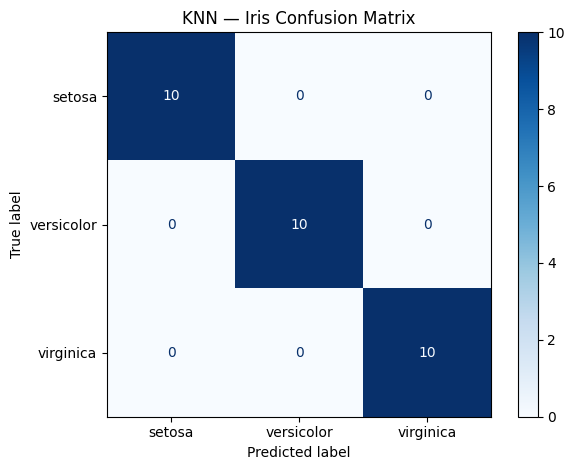

In [ ]:
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42, stratify=y)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

#Accuracy
acc = accuracy_score(y_test, y_pred)
print(f'Test accuracy: {acc:.1%}')

#Confusion matrix (rows actual, columns predicted)
cm = confusion_matrix(y_test, y_pred)
print('Confusion matrix (actual rows, predicted columns):')
print(cm)

# Display with class labels
disp = ConfusionMatrixDisplay(
confusion_matrix=cm,
display_labels=iris.target_names
)
disp.plot(cmap='Blues')
plt.title('KNN — Iris Confusion Matrix')
plt.tight_layout()
plt.savefig('confusion_matrix_knn.png', dpi=100)
plt.show()

# Markdown cell — interpret the matrix:
# 'Misclassifications: [list each off-diagonal cell].
# The model most commonly confuses [class A] with [class B] because...'


# Notebook: G5-MS-L06_classification_report.ipynb
**bold text**

In [4]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix

iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42, stratify=y)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

print(classification_report(y_test, y_pred,
target_names=iris.target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



#Write in a markdown cel for each class:
#'For class[X]:',
#'Precision = [Y]: when the model predicted[X], it was right[Y]% of the time.'
#'Recall = [Z]: of all actual [X] examples, the model found [Z]%.'
#'F1 = [W]: the balance between precision and recall'